# 📡 AI/ML for 5G Handover: Supervised vs Time-Series Prediction

**Course project: Resource Management in Wireless Networks (UPT)**

A conventional handover rule is *reactive*: it waits until a neighbor cell is already stronger. This notebook asks whether a model can **predict the best cell ahead of time** and compares two approaches on identical data:

| Approach | Model | Idea |
|---|---|---|
| 🟦 Baseline | strongest cell now | reactive reference (simplified stand-in for A3) |
| 🟧 Supervised | XGBoost | hand-made features → classify the best future cell |
| 🟦 Time-series | LSTM | raw RSRP sequence → forecast future RSRP → pick the best cell |

**Pipeline:** simulator → dataset → models → evaluation tables → charts → conclusions.

## ⚙️ 1. Setup and configuration

In [1]:
import time, copy, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from xgboost import XGBClassifier
from sklearn.model_selection import GroupShuffleSplit
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False})

SEED = 42
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# ---- radio scenario ----
DT = 0.5               # time step [s]
T_STEPS = 600          # 5 minutes per user
ISD = 250.0            # inter-site distance [m]
FC = 3.5               # carrier frequency [GHz]
TX = 30.0              # simplified per-cell reference power [dBm]
SIGMA_SH = 6.0         # shadowing std [dB]
D_CORR = 50.0          # shadowing decorrelation distance [m]
NOISE_STD = 1.0        # measurement noise [dB]
SPEEDS = (3, 30, 60, 120)   # km/h
N_USERS = 400

# ---- learning task ----
WINDOW = 10            # past samples (5 s) seen by both models
HORIZON = 30           # future samples (15 s) defining the label
DSCALE = 10.0          # scale of the LSTM target [dB]
N_SPLITS = 3
EPOCHS = 25

COLORS = {"Baseline": "#94A3B8", "XGBoost": "#F59E0B", "LSTM": "#3B82F6"}
MODELS = list(COLORS)
print(f"Running on: {DEVICE}")

Running on: cuda


## 🛰️ 2. Radio simulator

- 3x3 grid of base stations, users moving with random direction changes and reflecting borders
- Simplified path loss: `32.4 + 20 log10(fc) + 30 log10(d)`
- Spatially correlated **shadowing** (AR(1) process, decorrelation depends on speed) plus measurement noise

> **Label:** the cell with the highest *average RSRP over the next 15 s*. It is a prediction target, not just the current best cell, so the task is not trivial.

In [2]:
gx, gy = np.meshgrid(np.arange(3), np.arange(3))
BS = np.stack([gx.ravel(), gy.ravel()], axis=1) * ISD
N_BS = len(BS)
LOW, HIGH = -ISD / 2, 2 * ISD + ISD / 2

def simulate_user(speed_kmh):
    v = speed_kmh / 3.6
    pos = rng.uniform(LOW, HIGH, size=2)
    heading = rng.uniform(0, 2 * np.pi)
    rho = np.exp(-v * DT / D_CORR)
    shadow = rng.normal(0, SIGMA_SH, N_BS)
    rsrp = np.zeros((T_STEPS, N_BS))
    track = np.zeros((T_STEPS, 2))
    for t in range(T_STEPS):
        if rng.random() < 0.05:
            heading += rng.normal(0, np.pi / 6)
        pos = pos + v * DT * np.array([np.cos(heading), np.sin(heading)])
        for k in range(2):
            if pos[k] < LOW or pos[k] > HIGH:
                heading = np.pi - heading if k == 0 else -heading
                pos[k] = np.clip(pos[k], LOW, HIGH)
        d = np.maximum(np.linalg.norm(BS - pos, axis=1), 10.0)
        pl = 32.4 + 20 * np.log10(FC) + 30 * np.log10(d)
        shadow = rho * shadow + np.sqrt(1 - rho ** 2) * rng.normal(0, SIGMA_SH, N_BS)
        rsrp[t] = TX - pl - shadow + rng.normal(0, NOISE_STD, N_BS)
        track[t] = pos
    return rsrp, track

def build_dataset(n_users):
    F, W, Yf, groups = [], [], [], []
    for u in range(n_users):
        sp = SPEEDS[u % len(SPEEDS)]
        rsrp, _ = simulate_user(sp)
        for t in range(WINDOW, T_STEPS - HORIZON):
            past = rsrp[t - WINDOW:t]
            last = past[-1]
            F.append(np.concatenate([last,                 # current RSRP of every cell
                                     last - past[-3],      # short-term trend
                                     last - past[0],       # long-term trend
                                     past.std(axis=0),     # variability
                                     [sp]]))               # user speed
            W.append(past)                                 # raw sequence for the LSTM
            Yf.append(rsrp[t:t + HORIZON].mean(axis=0))    # mean future RSRP per cell
            groups.append(u)
    F = np.array(F, dtype=np.float32)
    W = np.array(W, dtype=np.float32)
    Yf = np.array(Yf, dtype=np.float32)
    return F, W, Yf, Yf.argmax(1), np.array(groups)

t0 = time.time()
F, W, Yf, y, groups = build_dataset(N_USERS)
speed_all = F[:, -1]
cur_all = W[:, -1, :].argmax(1)        # baseline: strongest cell right now
change_all = y != cur_all              # samples where the best future cell differs

display(pd.DataFrame({
    "Users": N_USERS, "Samples": len(y), "XGBoost features": F.shape[1],
    "LSTM input": f"{WINDOW} steps x {N_BS} cells", "Classes (cells)": N_BS,
    "Best-cell changes": f"{change_all.mean():.1%}", "Build time": f"{time.time() - t0:.0f}s",
}, index=["Dataset"]).T)

,Dataset
Users,400
Samples,224000
XGBoost features,37
LSTM input,10 steps x 9 cells
Classes (cells),9
Best-cell changes,37.9%
Build time,17s


## 🔍 3. A look at the scenario

Left: network layout and one 60 km/h trajectory. Middle: RSRP of all cells along that trajectory (the black line is the strongest cell, which is what a reactive rule follows). Right: the faster the user, the more often the best cell changes, and that is where prediction can help.

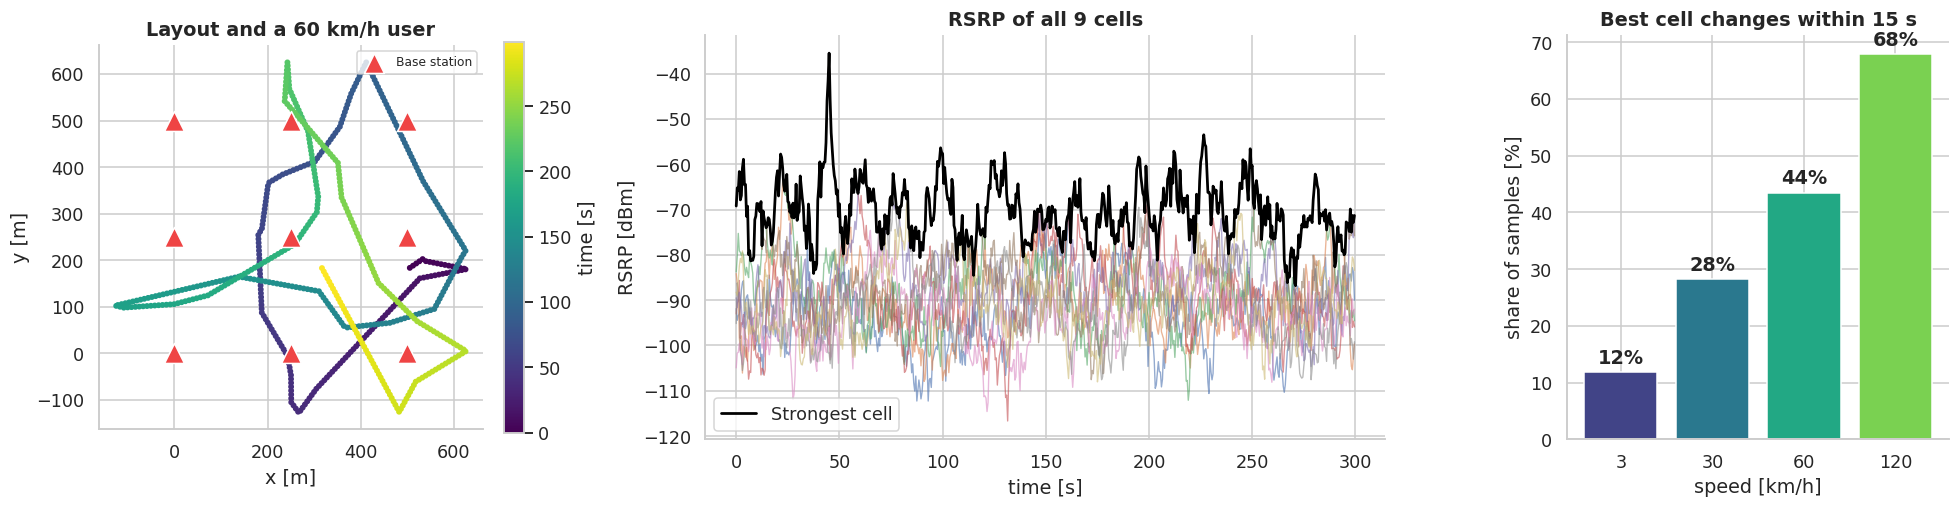

In [3]:
demo_rsrp, demo_track = simulate_user(60)
t_axis = np.arange(T_STEPS) * DT

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), gridspec_kw={"width_ratios": [1, 1.6, 0.9]})

ax = axes[0]
ax.scatter(BS[:, 0], BS[:, 1], marker="^", s=170, color="#EF4444", edgecolor="white", zorder=3, label="Base station")
sc = ax.scatter(demo_track[:, 0], demo_track[:, 1], c=t_axis, cmap="viridis", s=8, zorder=2)
plt.colorbar(sc, ax=ax, label="time [s]", fraction=0.046)
ax.set(title="Layout and a 60 km/h user", xlabel="x [m]", ylabel="y [m]")
ax.set_aspect("equal")
ax.legend(loc="upper right", fontsize=8)

ax = axes[1]
for c in range(N_BS):
    ax.plot(t_axis, demo_rsrp[:, c], lw=0.9, alpha=0.6)
ax.plot(t_axis, demo_rsrp.max(1), color="black", lw=1.8, label="Strongest cell")
ax.set(title="RSRP of all 9 cells", xlabel="time [s]", ylabel="RSRP [dBm]")
ax.legend(loc="lower left")

ax = axes[2]
share = pd.Series(change_all).groupby(speed_all).mean()
bars = ax.bar([f"{int(s)}" for s in share.index], share.values * 100,
              color=sns.color_palette("viridis", len(share)), edgecolor="white")
for b, v in zip(bars, share.values * 100):
    ax.annotate(f"{v:.0f}%", (b.get_x() + b.get_width() / 2, v), ha="center", va="bottom",
                xytext=(0, 3), textcoords="offset points", fontweight="bold")
ax.set(title="Best cell changes within 15 s", xlabel="speed [km/h]", ylabel="share of samples [%]")
plt.tight_layout()
plt.show()

## 🧠 4. Models

**Supervised (XGBoost):** engineered features (current RSRP, short/long trends, variability, speed) → direct classification of the best future cell.

**Time-series (LSTM):** a 2-layer LSTM reads the raw 10-step RSRP sequence and forecasts the *change* in mean future RSRP of every cell; the cell with the highest forecast is chosen. Forecasting the delta instead of the absolute value makes learning much easier.

Both see the **same information** (the last 5 s of RSRP and the speed), so any difference comes from the model type.

In [4]:
class LSTMForecaster(nn.Module):
    def __init__(self, n_cells, hidden=64):
        super().__init__()
        self.lstm = nn.LSTM(n_cells, hidden, num_layers=2, batch_first=True, dropout=0.1)
        self.head = nn.Sequential(nn.Linear(hidden + 1, 64), nn.ReLU(), nn.Linear(64, n_cells))

    def forward(self, x, speed):
        out, _ = self.lstm(x)
        return self.head(torch.cat([out[:, -1], speed], dim=1))


def train_lstm(data_tr, data_va, epochs=EPOCHS, bs=512, lr=1e-3):
    Wtr, Str, Dtr = data_tr
    Wva, Sva, Dva = data_va
    model = LSTMForecaster(N_BS).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    best, best_state, n = float("inf"), None, len(Wtr)
    hist = {"train": [], "val": []}
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(n, device=DEVICE)
        run = 0.0
        for i in range(0, n, bs):
            idx = perm[i:i + bs]
            loss = nn.functional.mse_loss(model(Wtr[idx], Str[idx]), Dtr[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()
            run += loss.item() * len(idx)
        model.eval()
        with torch.no_grad():
            val = nn.functional.mse_loss(model(Wva, Sva), Dva).item()
        hist["train"].append(run / n)
        hist["val"].append(val)
        if val < best:
            best, best_state = val, copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)      # early stopping: keep the best epoch
    return model, hist


print(f"LSTM parameters: {sum(p.numel() for p in LSTMForecaster(N_BS).parameters()):,}")

LSTM parameters: 57,289


## 🧪 5. Experiments

Evaluation is repeated on **3 splits made by user** (never by row), because consecutive samples of one trajectory are almost identical and a row-wise split would leak information. The LSTM validation set is carved out of the *training* users only.

In [5]:
rows, speed_rows, rmse_rows, histories = [], [], [], {}
splitter = GroupShuffleSplit(n_splits=N_SPLITS, test_size=0.2, random_state=0)

def evaluate(name, pred, yt, cur, sp_te, split):
    change = yt != cur
    rows.append({"split": split, "model": name,
                 "acc": (pred == yt).mean(),
                 "change_acc": ((pred == yt) & change).sum() / change.sum(),
                 "false_change": ((pred != cur) & ~change).sum() / (~change).sum()})
    for s in SPEEDS:
        m = sp_te == s
        speed_rows.append({"split": split, "model": name, "speed": s, "acc": (pred[m] == yt[m]).mean()})

for i, (tr, te) in enumerate(splitter.split(F, y, groups)):
    yt, cur, sp_te = y[te], cur_all[te], speed_all[te]

    # --- supervised: XGBoost ---
    t0 = time.time()
    xgb = XGBClassifier(n_estimators=300, max_depth=8, learning_rate=0.1, tree_method="hist",
                        device=DEVICE, random_state=i).fit(F[tr], y[tr])
    pred_xgb = xgb.predict(F[te])
    t_xgb = time.time() - t0

    # --- time series: LSTM ---
    sub_tr, sub_va = next(GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=i).split(tr, groups=groups[tr]))
    tr_a, tr_v = tr[sub_tr], tr[sub_va]
    mu, sd = W[tr_a].mean(), W[tr_a].std()

    def prep(idx):
        w = torch.tensor((W[idx] - mu) / sd, device=DEVICE)
        s = torch.tensor(speed_all[idx] / 120.0, device=DEVICE).unsqueeze(1)
        d = torch.tensor((Yf[idx] - W[idx][:, -1, :]) / DSCALE, device=DEVICE)
        return w, s, d

    t0 = time.time()
    model, hist = train_lstm(prep(tr_a), prep(tr_v))
    t_lstm = time.time() - t0
    histories[i] = hist

    Wte, Ste, _ = prep(te)
    model.eval()
    with torch.no_grad():
        delta = model(Wte, Ste).cpu().numpy() * DSCALE
    last_te = W[te][:, -1, :]
    fut_pred = last_te + delta
    pred_lstm = fut_pred.argmax(1)

    rmse_rows.append({"split": i, "forecast": "LSTM", "rmse": np.sqrt(((fut_pred - Yf[te]) ** 2).mean())})
    rmse_rows.append({"split": i, "forecast": "Persistence", "rmse": np.sqrt(((last_te - Yf[te]) ** 2).mean())})

    for name, pred in [("Baseline", cur), ("XGBoost", pred_xgb), ("LSTM", pred_lstm)]:
        evaluate(name, pred, yt, cur, sp_te, i)
    print(f"split {i}: XGBoost {t_xgb:.0f}s | LSTM {t_lstm:.0f}s")

res = pd.DataFrame(rows)
speed_df = pd.DataFrame(speed_rows)
rmse_df = pd.DataFrame(rmse_rows)

split 0: XGBoost 18s | LSTM 34s
split 1: XGBoost 17s | LSTM 22s
split 2: XGBoost 17s | LSTM 22s


## 📊 6. Results

**Metrics**
- **Accuracy**: predicted best future cell equals the true one
- **Correct on change**: accuracy only on samples where the best cell actually changes (the reactive baseline scores 0 here by construction)
- **False change**: how often a model proposes a different cell when nothing should change (a proxy for ping-pong risk, lower is better)

In [6]:
names = {"acc": "Accuracy", "change_acc": "Correct on change", "false_change": "False change (lower = better)"}

mean_tbl = res.groupby("model")[list(names)].mean().loc[MODELS].rename(columns=names)
std_tbl = res.groupby("model")[list(names)].std().loc[MODELS].rename(columns=names)

display(mean_tbl.style
        .format("{:.3f}")
        .background_gradient(cmap="Greens", subset=["Accuracy", "Correct on change"])
        .background_gradient(cmap="Reds", subset=["False change (lower = better)"])
        .set_caption("Mean over 3 user-based splits"))
display(std_tbl.style.format("{:.3f}").set_caption("Standard deviation over splits"))

,Accuracy,Correct on change,False change (lower = better)
model,,,
Baseline,0.623,0.000,0.000
XGBoost,0.652,0.247,0.103
LSTM,0.656,0.195,0.065


,Accuracy,Correct on change,False change (lower = better)
model,,,
Baseline,0.017,0.000,0.000
XGBoost,0.012,0.004,0.004
LSTM,0.012,0.011,0.003


In [7]:
pv = speed_df.pivot_table(index="model", columns="speed", values="acc").loc[MODELS]
pv.columns = [f"{c} km/h" for c in pv.columns]

display(pv.style
        .format("{:.3f}")
        .background_gradient(cmap="YlGnBu", axis=0)
        .set_caption("Accuracy by user speed (colour scale per column)"))

,3 km/h,30 km/h,60 km/h,120 km/h
model,,,,
Baseline,0.873,0.720,0.566,0.313
XGBoost,0.861,0.726,0.590,0.414
LSTM,0.871,0.730,0.593,0.413


### 📈 Charts

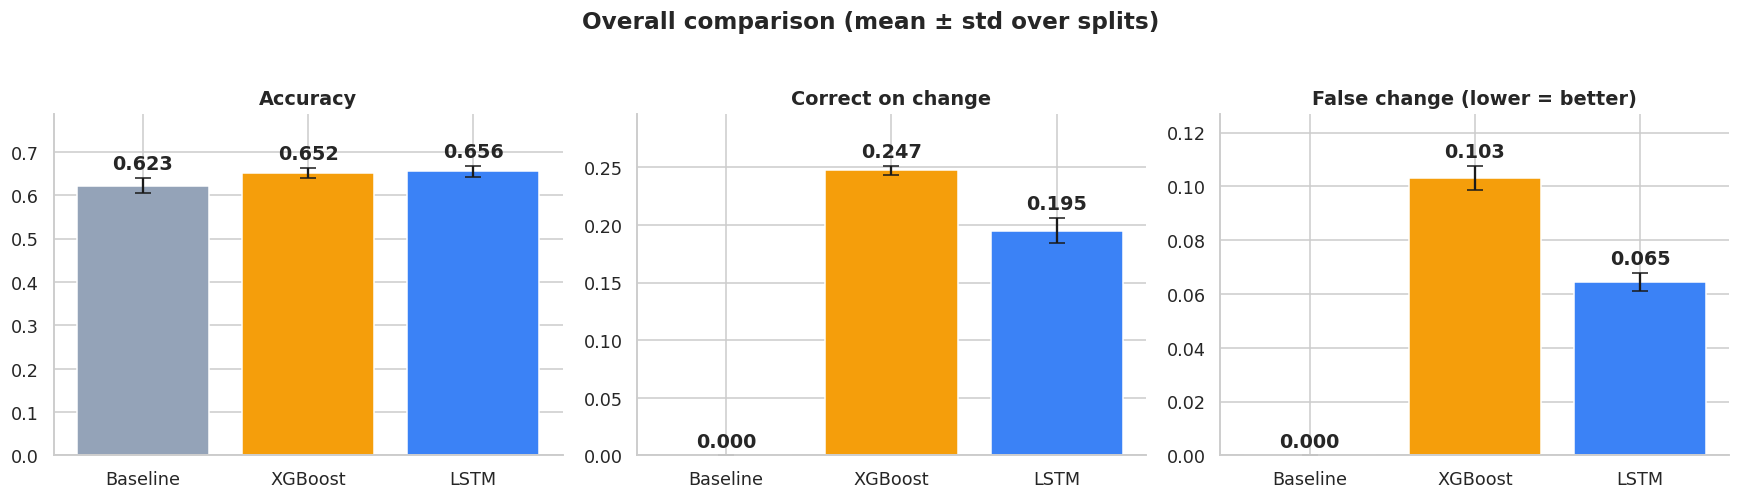

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for ax, (col, title) in zip(axes, names.items()):
    m = res.groupby("model")[col].agg(["mean", "std"]).loc[MODELS]
    ax.bar(MODELS, m["mean"], yerr=m["std"], capsize=5, color=[COLORS[k] for k in MODELS], edgecolor="white")
    for x, (v, s) in enumerate(zip(m["mean"], m["std"])):
        ax.annotate(f"{v:.3f}", (x, v + s), ha="center", va="bottom", xytext=(0, 3),
                    textcoords="offset points", fontweight="bold")
    ax.set_title(title)
    ax.set_ylim(0, max(m["mean"] + m["std"]) * 1.18)
fig.suptitle("Overall comparison (mean ± std over splits)", fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

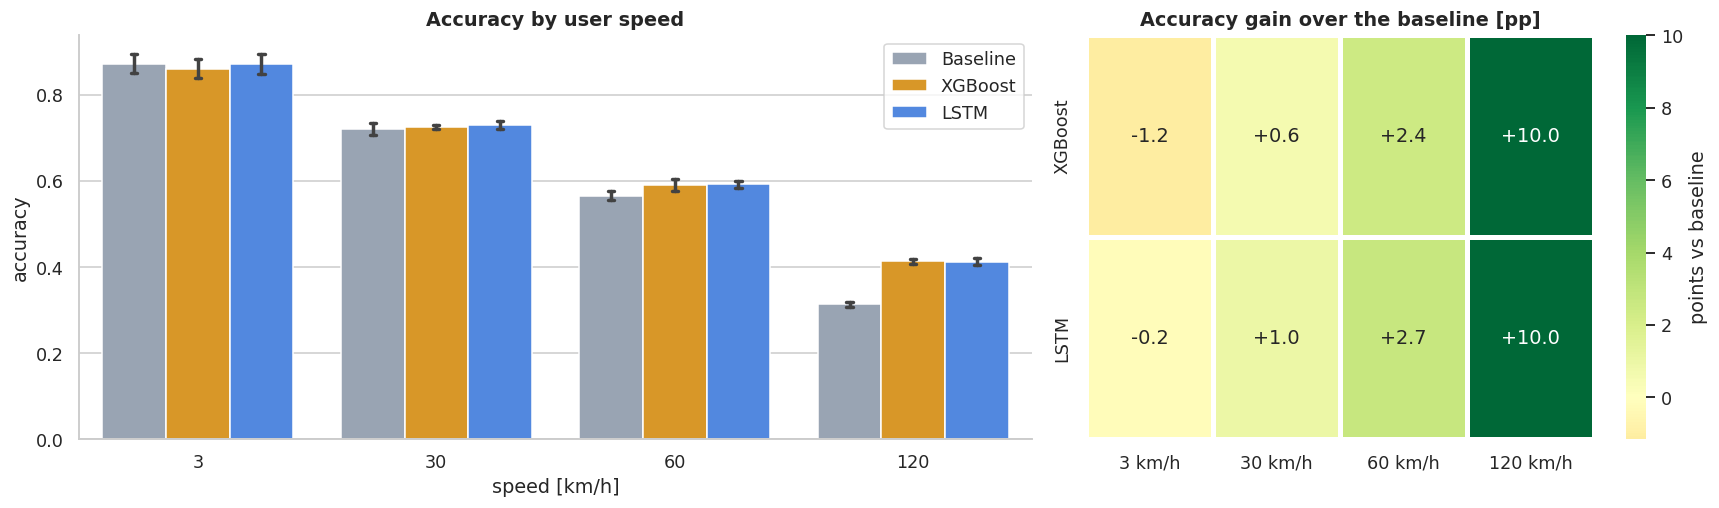

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})

sns.barplot(data=speed_df, x="speed", y="acc", hue="model", hue_order=MODELS,
            palette=COLORS, errorbar="sd", capsize=0.08, edgecolor="white", ax=axes[0])
axes[0].set(title="Accuracy by user speed", xlabel="speed [km/h]", ylabel="accuracy")
axes[0].legend(title="", loc="upper right")

gain = (pv.drop("Baseline") - pv.loc["Baseline"]) * 100
sns.heatmap(gain, annot=True, fmt="+.1f", cmap="RdYlGn", center=0, linewidths=2,
            linecolor="white", cbar_kws={"label": "points vs baseline"}, ax=axes[1])
axes[1].set(title="Accuracy gain over the baseline [pp]", xlabel="", ylabel="")
plt.tight_layout()
plt.show()

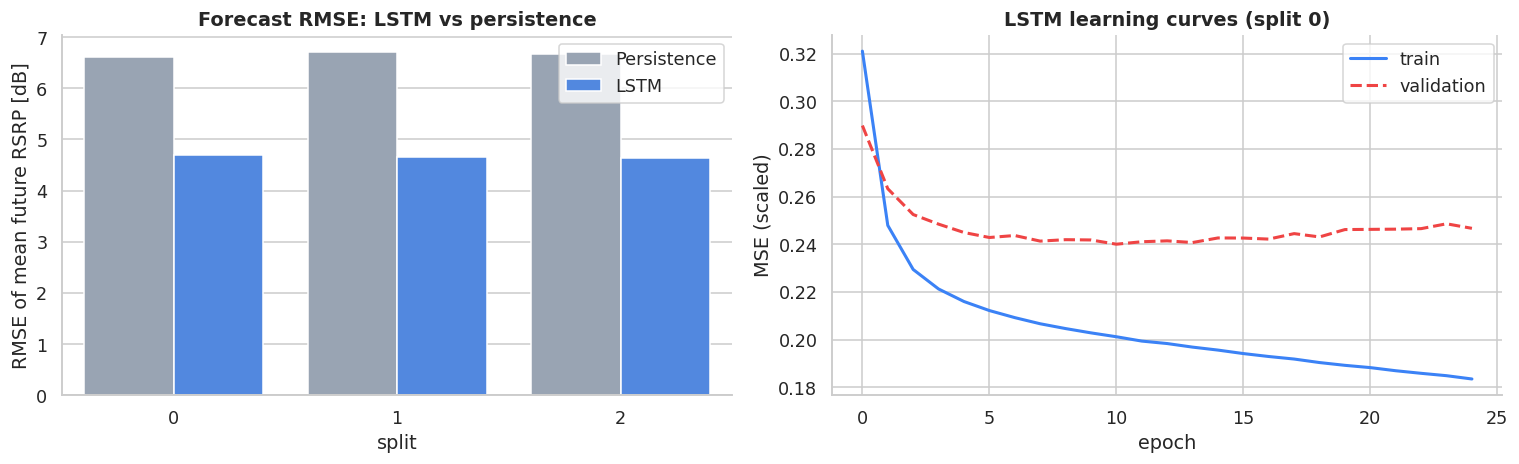

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))

sns.barplot(data=rmse_df, x="split", y="rmse", hue="forecast", hue_order=["Persistence", "LSTM"],
            palette={"Persistence": COLORS["Baseline"], "LSTM": COLORS["LSTM"]}, edgecolor="white", ax=axes[0])
axes[0].set(title="Forecast RMSE: LSTM vs persistence", xlabel="split", ylabel="RMSE of mean future RSRP [dB]")
axes[0].legend(title="")

h = histories[0]
axes[1].plot(h["train"], color=COLORS["LSTM"], lw=2, label="train")
axes[1].plot(h["val"], color="#EF4444", lw=2, ls="--", label="validation")
axes[1].set(title="LSTM learning curves (split 0)", xlabel="epoch", ylabel="MSE (scaled)")
axes[1].legend()
plt.tight_layout()
plt.show()

## 🧾 7. Automatic summary

In [11]:
mean_acc = res.groupby("model")["acc"].mean()
best = mean_acc.drop("Baseline").idxmax()
print(f"Best learned model overall: {best} "
      f"({(mean_acc[best] - mean_acc['Baseline']) * 100:+.1f} pp accuracy vs the reactive baseline)\n")

for s in SPEEDS:
    col = f"{s} km/h"
    row = pv[col]
    winner = row.idxmax()
    print(f"{s:>4} km/h -> best: {winner:<9} | " + " | ".join(f"{m} {row[m]:.3f}" for m in MODELS))

rm = rmse_df.groupby("forecast")["rmse"].mean()
print(f"\nForecast RMSE: LSTM {rm['LSTM']:.2f} dB vs persistence {rm['Persistence']:.2f} dB")

Best learned model overall: LSTM (+3.4 pp accuracy vs the reactive baseline)

   3 km/h -> best: Baseline  | Baseline 0.873 | XGBoost 0.861 | LSTM 0.871
  30 km/h -> best: LSTM      | Baseline 0.720 | XGBoost 0.726 | LSTM 0.730
  60 km/h -> best: LSTM      | Baseline 0.566 | XGBoost 0.590 | LSTM 0.593
 120 km/h -> best: XGBoost   | Baseline 0.313 | XGBoost 0.414 | LSTM 0.413

Forecast RMSE: LSTM 4.67 dB vs persistence 6.66 dB


## ✅ 8. Discussion

**How to read the results**
- Prediction helps most for **fast users**, where the best cell changes often. At low speed the best cell is almost always the current one, so a learned model has little to add and may even trigger unnecessary changes.
- **Correct on change** is the most telling metric. It shows whether a model finds the right target when a handover is really needed, which the accuracy alone hides.
- If the LSTM does not beat the **persistence** forecast in RMSE, it has not learned anything useful beyond "the signal stays the same".

**Limitations (be honest about them in the report)**
- Simplified channel model: no SINR, interference, load, beamforming, or handover interruption time.
- The metrics are prediction-level. A model with good accuracy can still cause ping-pong or radio link failures when used as a real policy.
- Results come from one simulator configuration and a limited number of splits.

**Next step: closed-loop evaluation.** Plug A3 (with hysteresis and time-to-trigger), XGBoost, and the LSTM into the simulator as actual handover policies and compare **handover count, ping-pong rate, RLF rate, and average SINR** per speed. That is the evaluation that matches the course topic.